# Visión por Computador - Práctica 3 - Deep Learning en Computer Vision

#### 20 puntos   |   Fecha de entrega: 20 de diciembre de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2627.ugr.es/

### Estudiante: <mark>POR FAVOR, INTRODUZCA AQUÍ SU NOMBRE COMPLETO</mark>

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero” (salvo que se indique lo contrario explícitamente en un ejercicio concreto; por ejemplo, si un ejercicio determina una ubicación propia para un determinado conjunto de datos).

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.

Este trabajo de implementación tiene como objetivo principal **familiarizarse con la implementación y diseño de redes convolucionales para problemas de visión por computador**.




### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83733):
-  Introducción a Python: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/2.%20Introducci%C3%B3n%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf(y Notebook asociado: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Algunas%20ideas%20sobre%20c%C3%B3mo%20elaborar%20un%20informe%20acad%C3%A9mico-cient%C3%ADfico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2627.ugr.es/pluginfile.php/153448/mod_folder/content/0/Ejemplo_Otsu.ipynb

# <font color='blue'>**Ejercicio  3: Transfer Learning y fine-tuning con ResNet50 en el SPR X-Ray Age Prediction Challenge (5 puntos)**
<font color='blue'>En este ejercicio trabajaremos con el _SPR X-Ray Age Prediction Challenge_ de Kaggle (https://www.kaggle.com/competitions/spr-x-ray-age/data). Este dataset consta de $10 702$ radiografías de tórax, y el objetivo es predecir la edad de la persona a partir de la imagen de la radiografía. En esta ocasión, se emplearán $6 702$ imágenes para entrenamiento y $4 000$ para test. Las edades oscilan entre los 18 y los 89 años. Para facilitar el trabajo al alumnado se proporciona una versión procesada de los datos (con resolución $224\times224$, en lugar de $1024\times1024$, y empleando solo ejemplos para los cuales se tiene salida deseada (dado que, al tratarse de una challenge de kaggle, el conjunto de test está disponible pero sin etiquetar)). Estos datos se pueden acceder desde: https://drive.google.com/drive/folders/1hCWfTLs1w0h5kObl6NEIhEtH5VDmmCnj?usp=sharing (se debe emplear una cuenta de la UGR para acceder a dicha URL, y la información allí contenida (directorio `spr-x-ray-age`) se debe incluir en la carpeta `Colab Notebooks`).

<font color='blue'>Se debe emplear un $25\%$ de los datos de entrenamiento para validación, y el rendimiento debe ser evaluado, como mínimo, por medio de $MSE$, $MAE$ y $R^2$ _(coefficient of determination) score_. Se deben justificar las decisiones tomadas, como la elección de la función de pérdida. Del mismo modo, es necesario hacer un `summary()` de las arquitecturas empleadas en cada apartado, indicando qué parámetros/capas/bloques son entrenables y cuáles no lo son (es decir, en cada apartado es imprescindible destacar claramente qué arquitectura exacta se está utilizando, así como qué pesos se están entrenando y cuáles se están congelando).

<font color='blue'>En los primeros cuatro apartados utilizaremos ResNet50 como arquitectura de referencia, partiendo de pesos aleatorios o preentrenados en ImageNet según corresponda. En el apartado 3.5 se podrá utilizar una arquitectura alternativa. Tendremos que realizar los experimentos y responder las preguntas, que se muestran a continuación:

  <font color='blue'>
  
  1. (0.75 puntos) Partimos de ResNet50, adaptamos la cabecera (sustituyendo la cabecera anterior por *una única fully-connected* con el número de neuronas de salida adecuado), y reentrenamos (_from scratch_) la red entera para este nuevo problema durante $15$ épocas. Es decir, partimos de pesos aleatorios para resolver este problema de regresión.

  <font color='blue'>

  2. <font color='blue'> (1.25 puntos, incluidos los 0.5 puntos de las dos cuestiones adicionales descritas más abajo) Partimos de ResNet50, adaptamos la cabecera (empleando exactamente la misma del apartado anterior), y entrenamos única y exclusivamente la cabecera incorporada. Es decir, ResNet50 se usa como un mero extractor de características (preentrenado en ImageNet), y los pesos que se entrenan  durante $15$ épocas son los de la nueva capa incorporada (manteniendo fijos/congelados todos los demás). Como parte de este apartado se deben responder las dos siguientes preguntas:
  
      - <font color='blue'> (0.25 puntos) Si no se especifica ninguna custom_head, ¿qué arquitectura incorpora fastai por defecto? Entrena el modelo utilizando dicha cabecera, manteniendo congelado el backbone, y compara sus resultados con los obtenidos mediante la cabecera personalizada. ¿Qué diferencias existen entre ambas arquitecturas? ¿Qué conclusiones puedes extraer en términos de rendimiento y número de parámetros entrenables?
      - <font color='blue'> (0.25 puntos) Estamos intentando resolver un problema de regresión por medio de la reutilización de un modelo pre-entrenado en un problema de clasificación (ImageNet). ¿Tiene sentido hacerlo? ¿Por qué nos sirven pesos entrenados en clasificación para un problema de regresión? ¿No son, acaso, problemáticas muy diferentes?

  <font color='blue'>

3. <font color='blue'>(0.75 puntos) Partimos de ResNet50 preentrenada en ImageNet, empleamos la misma cabecera personalizada utilizada en los apartados 3.1 y 3.2 y realizamos un ajuste fino de toda la red durante $15$ épocas: $5$ para la cabecera y $10$ para toda la red.



4. <font color='blue'>(1 punto) Partimos de ResNet50 preentrenada en ImageNet, y empleamos una cabecera con la misma estructura que en los apartados anteriores, adaptando el número de neuronas de salida al nuevo problema de clasificación (72 clases, correspondientes a las edades enteras comprendidas entre $18$ y $89$ años), y realizamos un ajuste fino de toda la red durante $15$ épocas: $5$ para la cabecera y $10$ para toda la red. Es decir, en este caso, enfocamos el problema como uno de clasificación con tantas clases como años contiene nuestro dataset. El alumnado debe emplear, al menos, dos métricas de clasificación para evaluar el rendimiento. Además de las métricas de clasificación, calcula $MSE$, $MAE$ y $R^2$ convirtiendo las clases predichas en edades numéricas, para facilitar la comparación con los experimentos de regresión. ¿Qué conclusiones extrae de este experimento? ¿Qué aproximación, a priori, parece más adecuada: regresión o clasificación?

5. <font color='blue'>(1 punto) En este último apartado, se deberá diseñar e implementar una arquitectura alternativa para estimar la edad de los individuos a partir de sus radiografías de tórax, intentando mejorar los resultados obtenidos en los apartados anteriores. El alumnado tendrá libertad para diseñar una arquitectura propia o reutilizar componentes de arquitecturas existentes, incluidos modelos preentrenados, siempre que introduzca modificaciones arquitectónicas justificadas. No será suficiente con modificar exclusivamente los hiperparámetros de entrenamiento, y se deberá entrenar, al igual que en los apartados anteriores, por $15$ épocas. Se deberán justificar las decisiones de diseño, describir la arquitectura propuesta y evaluar su rendimiento mediante las métricas utilizadas anteriormente. Finalmente, se deberán comparar los resultados con los obtenidos en los apartados anteriores, prestando especial atención al rendimiento predictivo, el número de parámetros y el tiempo de entrenamiento. No será obligatorio superar los resultados anteriores para obtener la máxima calificación. Se valorarán especialmente la justificación de las decisiones, la calidad de la experimentación y el análisis crítico de los resultados.

6. <font color='blue'> (0.25 puntos) En base a toda la experimentación realizada: ¿Qué conclusiones se pueden extraer? En caso de que nos enfrentemos a un nuevo problema, ¿qué opción, u opciones, de entre todas las anteriores, parece a priori la más razonable? ¿Por qué?

<font color='blue'>**Nota:** la restricción de utilizar una única capa fully connected, permitiendo únicamente una operación previa de flattening y sin incorporar capas de pooling, se aplica a las cabeceras personalizadas exigidas en los apartados 3.1, 3.2, 3.3 y 3.4. Esta restricción no se aplica al experimento adicional del apartado 3.2 que utiliza la cabecera predeterminada de fastai, ni al apartado 3.5, donde se permite diseñar una arquitectura alternativa.

In [ ]:
# The first thing we should do is to apply hardware acceleration via GPU. So, we have to go to Editar - Configuracion del Cuaderno - Acelerador por Hardware GPU

# Now we SET UP Fastai
!pip install -Uqq fastbook
!pip install nbdev
import fastbook
fastbook.setup_book()
import fastai
import fastcore
print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')
from nbdev.showdoc import *
from fastai.vision.all import *

  Attempting uninstall: fastcore
    Found existing installation: fastcore 2.2.33
    Uninstalling fastcore-2.2.33:
      Successfully uninstalled fastcore-2.2.33
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [nbdev]
Mounted at /content/gdrive
fastcore version 2.2.35 installed
fastai version 2.8.12 installed



### <font color='blue'>**Funciones auxiliares para visualizar las predicciones**

<font color='blue'>En este ejercicio proporcionamos dos funciones auxiliares para visualizar las predicciones de los modelos sobre imágenes del conjunto de validación. Estas funciones constituyen alternativas a `learn.show_results()`, que puede presentar problemas de compatibilidad relacionados con los mecanismos internos de visualización de determinadas versiones de fastai. Además de evitar depender de ese mecanismo, permiten personalizar la representación de los resultados.

### <font color='blue'>1. `show_regression_predictions(learn)`

<font color='blue'>Esta función está diseñada para los problemas de **regresión de edad** abordados en este ejercicio. Su funcionamiento es el siguiente:

1. Obtiene un minibatch del conjunto de validación.
2. Selecciona hasta 16 imágenes.
3. Ejecuta el modelo en modo evaluación, sin calcular gradientes.
4. Deshace las transformaciones necesarias para visualizar las imágenes.
5. Muestra una cuadrícula de 4 × 4 imágenes, indicando para cada una la edad real y la edad predicha.

<font color='blue'>Esto permite realizar una inspección cualitativa de las predicciones e identificar ejemplos con errores aparentemente elevados.

<font color='blue'>**Ejemplo de uso:**

```python
show_regression_predictions(learn1)
```

<font color='blue'>La función recibe como argumento el `Learner` previamente entrenado. En nuestra implementación, el número máximo de imágenes y el tamaño de la cuadrícula están fijados en el propio código.

### <font color='blue'>2. `show_classification_predictions(learn, nrows=4, ncols=4, seed=42)`

<font color='blue'>Esta función está diseñada para el problema de **clasificación de edades** abordado posteriormente en el ejercicio. Selecciona aleatoriamente imágenes del conjunto de validación, obtiene las predicciones del modelo y representa una cuadrícula con las etiquetas reales y predichas. Los títulos se colorean para facilitar la identificación de los resultados:
- <font color='blue'>**Verde:** predicción correcta.
- **Rojo:** predicción incorrecta.

<font color='blue'>La función dispone de tres argumentos:

| Argumento | Descripción |
|---|---|
| `learn` | `Learner` que contiene el modelo entrenado y los datos. |
| `nrows` | Número de filas de la cuadrícula. Por defecto, 4. |
| `ncols` | Número de columnas de la cuadrícula. Por defecto, 4. |
| `seed` | Semilla para seleccionar las imágenes de forma reproducible. Por defecto, 42. |

<font color='blue'>**Ejemplo de uso:**

```python
show_classification_predictions(learn4)
```

<font color='blue'>También podemos modificar el número de imágenes mostradas:

```python
show_classification_predictions(learn4, nrows=3, ncols=5, seed=42)
```

<font color='blue'>**Nota:** `show_classification_predictions()` utiliza internamente `learn.get_preds()`, que puede modificar el historial del `Recorder`. Por ello, conviene representar primero las curvas de entrenamiento con `learn.recorder.plot_metrics()`.



In [ ]:

# Muestra hasta 16 imágenes de validación con sus edades reales y predichas.
# Permite inspeccionar cualitativamente los errores de un modelo de regresión
# sin depender del mecanismo de visualización de learn.show_results().
# Realiza la inferencia directamente, sin calcular gradientes.
# Uso (después de entrenar): show_regression_predictions(learn1)
def show_regression_predictions(learn):
    # Número de imágenes que queremos visualizar (4 filas x 4 columnas).
    max_n = 16

    # Obtenemos un batch del conjunto de validación.
    dl = learn.dls.valid
    xb, yb = dl.one_batch()

    # Seleccionamos las primeras 16 imágenes del batch.
    n = min(max_n, len(xb))

    # Ponemos el modelo en modo evaluación.
    learn.model.eval()

    # Obtenemos las predicciones sin calcular gradientes.
    with torch.no_grad():
        preds = learn.model(xb[:n]).float().reshape(-1).cpu()

    # Deshacemos las transformaciones aplicadas a las imágenes,
    # incluida la normalización, para poder visualizarlas correctamente.
    samples = dl.decode_batch(
        (xb[:n], yb[:n]),
        max_n=n
    )

    # Creamos una figura con 4 filas y 4 columnas.
    fig, axes = plt.subplots(
        nrows=4,
        ncols=4,
        figsize=(16, 16)
    )

    # Recorremos las 16 posiciones de la cuadrícula.
    for i, ax in enumerate(axes.flat):

        # Ocultamos las posiciones sobrantes si hubiera menos de 16 imágenes.
        if i >= n:
            ax.axis("off")
            continue

        # Recuperamos la imagen y su edad real.
        img, age = samples[i]

        # Mostramos la imagen en su posición correspondiente.
        img.show(ctx=ax)

        # Añadimos la edad real y la predicción del modelo.
        ax.set_title(
            f"Real: {float(age):.0f} años\n"
            f"Predicción: {float(preds[i]):.1f} años",
            fontsize=11
        )

        # Ocultamos los ejes para mejorar la presentación.
        ax.axis("off")

    # Ajustamos los espacios entre imágenes.
    plt.tight_layout()
    plt.show()

In [ ]:

# Muestra imágenes de validación con sus clases reales y predichas.
# Los títulos aparecen en verde (acierto) o rojo (error).
# Permite configurar filas, columnas y semilla de selección.
# Utiliza internamente learn.get_preds(); representar antes las métricas.
# Uso: show_classification_predictions(learn4, nrows=4, ncols=4, seed=42)
def show_classification_predictions(learn, nrows=4, ncols=4, seed=42):
    """
    Muestra predicciones de clasificación sobre imágenes seleccionadas
    aleatoriamente del conjunto de validación.

    Verde: predicción correcta.
    Rojo: predicción incorrecta.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    from PIL import Image

    # Obtenemos las rutas de las imágenes de validación.
    files = list(learn.dls.valid_ds.items)

    # Determinamos cuántas imágenes vamos a visualizar.
    n = min(nrows * ncols, len(files))

    # Seleccionamos imágenes aleatoriamente de forma reproducible.
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(files), size=n, replace=False)
    selected_files = [files[int(i)] for i in indices]

    # Creamos un DataLoader conservando las etiquetas reales.
    dl = learn.dls.test_dl(selected_files, with_labels=True)

    # Obtenemos las etiquetas reales y las clases predichas.
    _, targs, decoded = learn.get_preds(
        dl=dl,
        with_decoded=True
    )

    # Recuperamos el vocabulario de clases.
    vocab = learn.dls.vocab

    # Creamos la cuadrícula de visualización.
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * 3.5, nrows * 3.5)
    )

    axes = np.asarray(axes).reshape(-1)

    for i, ax in enumerate(axes):

        # Ocultamos las posiciones sobrantes.
        if i >= n:
            ax.axis("off")
            continue

        # Cargamos y mostramos la imagen original.
        with Image.open(selected_files[i]) as image:
            img = image.convert("RGB")

        ax.imshow(img)

        # Convertimos los índices en etiquetas legibles.
        true_label = str(vocab[int(targs[i])])
        pred_label = str(vocab[int(decoded[i])])

        # Elegimos el color según la corrección de la predicción.
        correct = true_label == pred_label
        color = "green" if correct else "red"

        # Mostramos la clase real y la predicha.
        ax.set_title(
            f"Real: {true_label}\nPredicción: {pred_label}",
            color=color,
            fontsize=11
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# from fastai.vision.all import *
import pandas as pd
import os
# import warnings
# warnings.filterwarnings('ignore')

In [ ]:
# # We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Visualiza la evolución de las métricas registradas durante el entrenamiento.
# Permite comparar las métricas de entrenamiento y validación cuando ambas
# están disponibles, agrupándolas por nombre.
# Se incorpora a Recorder mediante @patch.
# Uso (después de entrenar): learn.recorder.plot_metrics()
# Adaptada a partir de la implementación de Ignacio Oguiza (https://forums.fast.ai/t/plotting-metrics-after-learning/69937).
@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.asarray(self.values, dtype=float)
    names = [name for name in self.metric_names[1:] if name != 'time']

    if metrics.ndim != 2 or metrics.shape[1] != len(names):
        raise ValueError("Metric names do not match recorded values.")

    # Group training and validation metrics by name
    grouped = {}
    for i, name in enumerate(names):
        if name.startswith('train_'):
            split, base = 'train', name[len('train_'):]
        elif name.startswith('valid_'):
            split, base = 'valid', name[len('valid_'):]
        else:
            split, base = 'valid', name

        grouped.setdefault(base, {})[split] = i

    n = len(grouped)

    if nrows is None and ncols is None:
        nrows = max(1, int(math.sqrt(n)))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None:
        nrows = int(np.ceil(n / ncols))
    elif ncols is None:
        ncols = int(np.ceil(n / nrows))

    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = np.asarray(axs).reshape(-1)

    epochs = np.arange(len(metrics))

    for ax, (name, cols) in zip(axs, grouped.items()):
        for split, color in [('train', '#1f77b4'), ('valid', '#ff7f0e')]:
            if split in cols:
                ax.plot(epochs, metrics[:, cols[split]],
                        color=color, label=split)

        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.legend(loc='best')

    for ax in axs[n:]:
        ax.set_axis_off()

    fig.tight_layout()
    plt.show()


# Versión adaptada de ShowGraphCallback para visualizar las pérdidas
# durante el entrenamiento, compatible con train_metrics=True/False.
# Identifica 'valid_loss' por su nombre para evitar seleccionar
# una métrica incorrecta cuando cambia el orden de los registros.
# Uso: learn.fit(15, cbs=[FixedShowGraphCallback()])
class FixedShowGraphCallback(ShowGraphCallback):

    def after_epoch(self):
        if not self.nb_batches:
            return

        rec = self.learn.recorder

        # Identify the validation loss by name
        names = rec.metric_names[1:-1]
        valid_idx = names.index('valid_loss')

        train_losses = [float(v) for v in rec.losses]
        valid_losses = [
            float(v[valid_idx]) for v in rec.values
        ]

        iters = range(len(train_losses))

        x_bounds = (
            0,
            (self.n_epoch - len(self.nb_batches)) *
            self.nb_batches[0] + len(train_losses)
        )

        y_bounds = (
            0,
            max(max(train_losses), max(valid_losses))
        )

        self.progress.mbar.update_graph(
            [
                (iters, train_losses),
                (self.nb_batches, valid_losses)
            ],
            x_bounds,
            y_bounds
        )




In [ ]:
!ls drive/MyDrive/Colab\ Notebooks/spr-x-ray-age/
# !ls gdrive/MyDrive/Colab\ Notebooks/spr-x-ray-age/

All_labels.csv	test  train


In [ ]:
# defining the paths to images and labels
train_folder = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/train'
test_folder = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/test'
# csv_path_train = 'gdrive/MyDrive/Colab Notebooks/spr-x-ray-age/train_age.csv'
# csv_path_test = 'gdrive/MyDrive/Colab Notebooks/spr-x-ray-age/test_age.csv'
csv_path = 'drive/MyDrive/Colab Notebooks/spr-x-ray-age/All_labels.csv'

In [ ]:
if os.path.exists(csv_path):
    print("CSV File exists!")
    # reading the labels dataframe
    df = pd.read_csv(csv_path, dtype=float, index_col=0)
    print(f'Dataframe shape: {df.shape}')
else:
    print("File does not exist.")

CSV File exists!
Dataframe shape: (10702, 1)


In [ ]:
# defining the dataset paths
train_path = Path(train_folder)
test_path = Path(test_folder)

# reading the folders looking for images
train_files = get_image_files(train_path)
test_files = sorted(get_image_files(test_path))

print(f'{len(train_files)} files were found for training and {len(test_files)} files were found for test')

6702 files were found for training and 4000 files were found for test


Age varies from 18.0 to 89.0



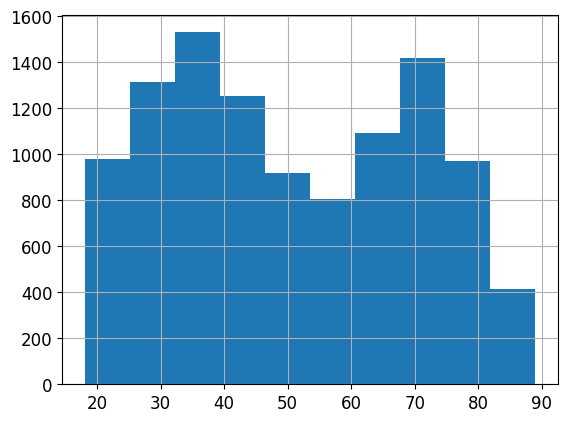

In [ ]:
print(f'Age varies from {df.age.min()} to {df.age.max()}\n')
_=df.age.hist()

In [ ]:
# function used to retun the label from an image
def label_func(file):
    # takes the file's base name w/o the extension
    basename = int(os.path.basename(str(file)).split('.')[0])

    # searches for the label
    label = int(df.age[basename])

    return label

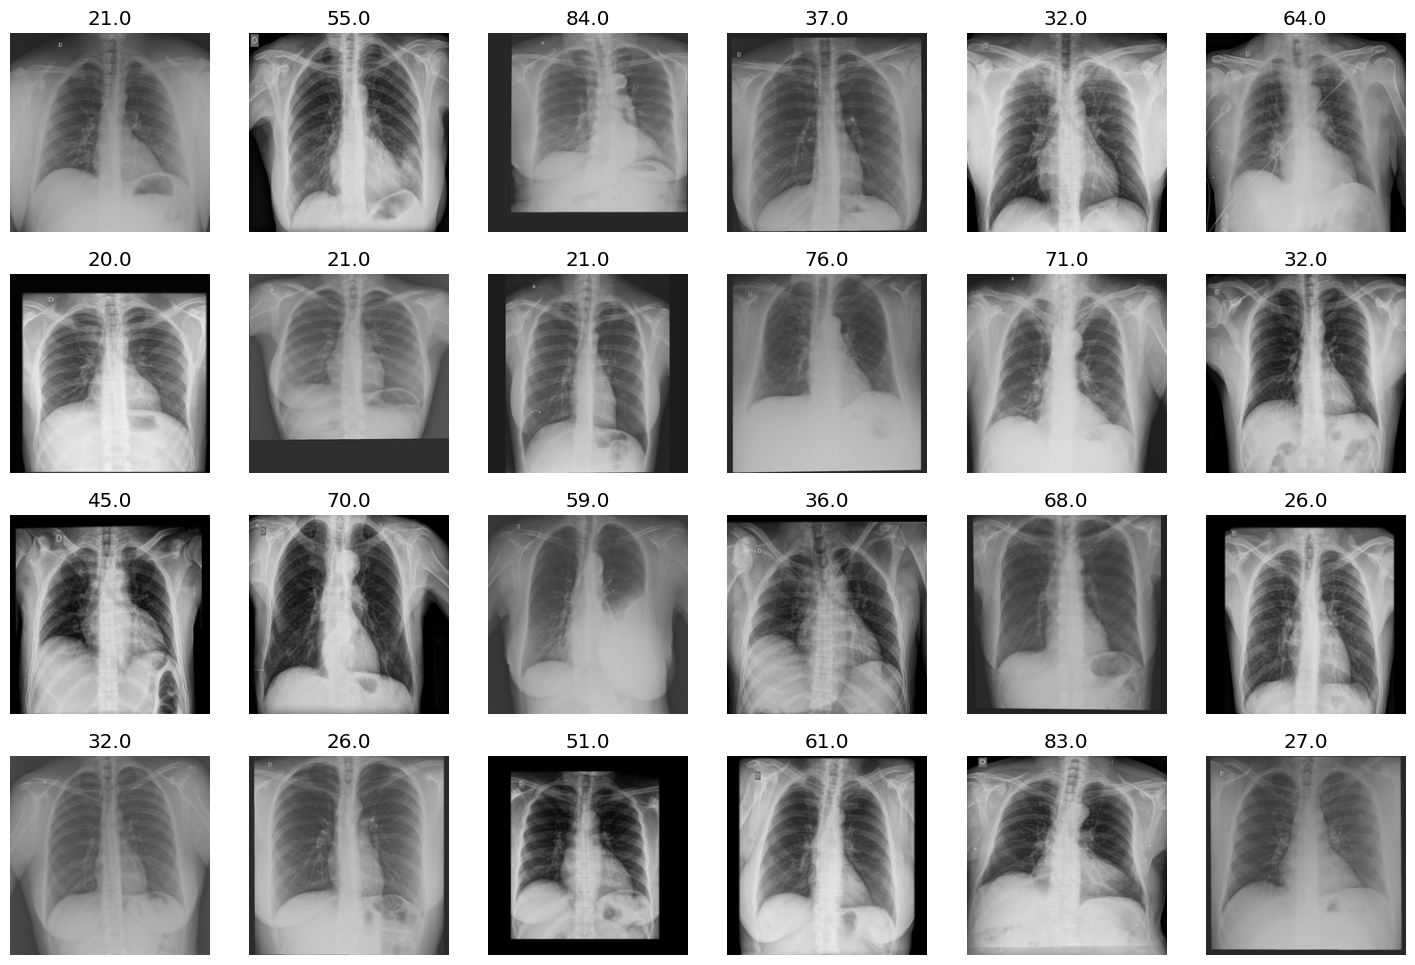

In [ ]:
dtblk = DataBlock(
    # A CUBRIR POR EL ALUMNADO
)
dls = dtblk.dataloaders(
    # A CUBRIR POR EL ALUMNADO
)

dls.show_batch(max_n=24)

In [ ]:
print('Numero de ejemplos de entrenamiento (una vez descartados los de validacion):', len(dls.train_ds))
print('Numero de ejemplos de validacion:', len(dls.valid_ds))

Numero de ejemplos de entrenamiento (una vez descartados los de validacion): 5027
Numero de ejemplos de validacion: 1675


## <font color='blue'>3.1. Entrenamos todo ResNet50 _from scratch_, ajustando la cabecera para este problema. (0.75 puntos)

In [ ]:
# A CUBRIR POR EL ALUMNADO


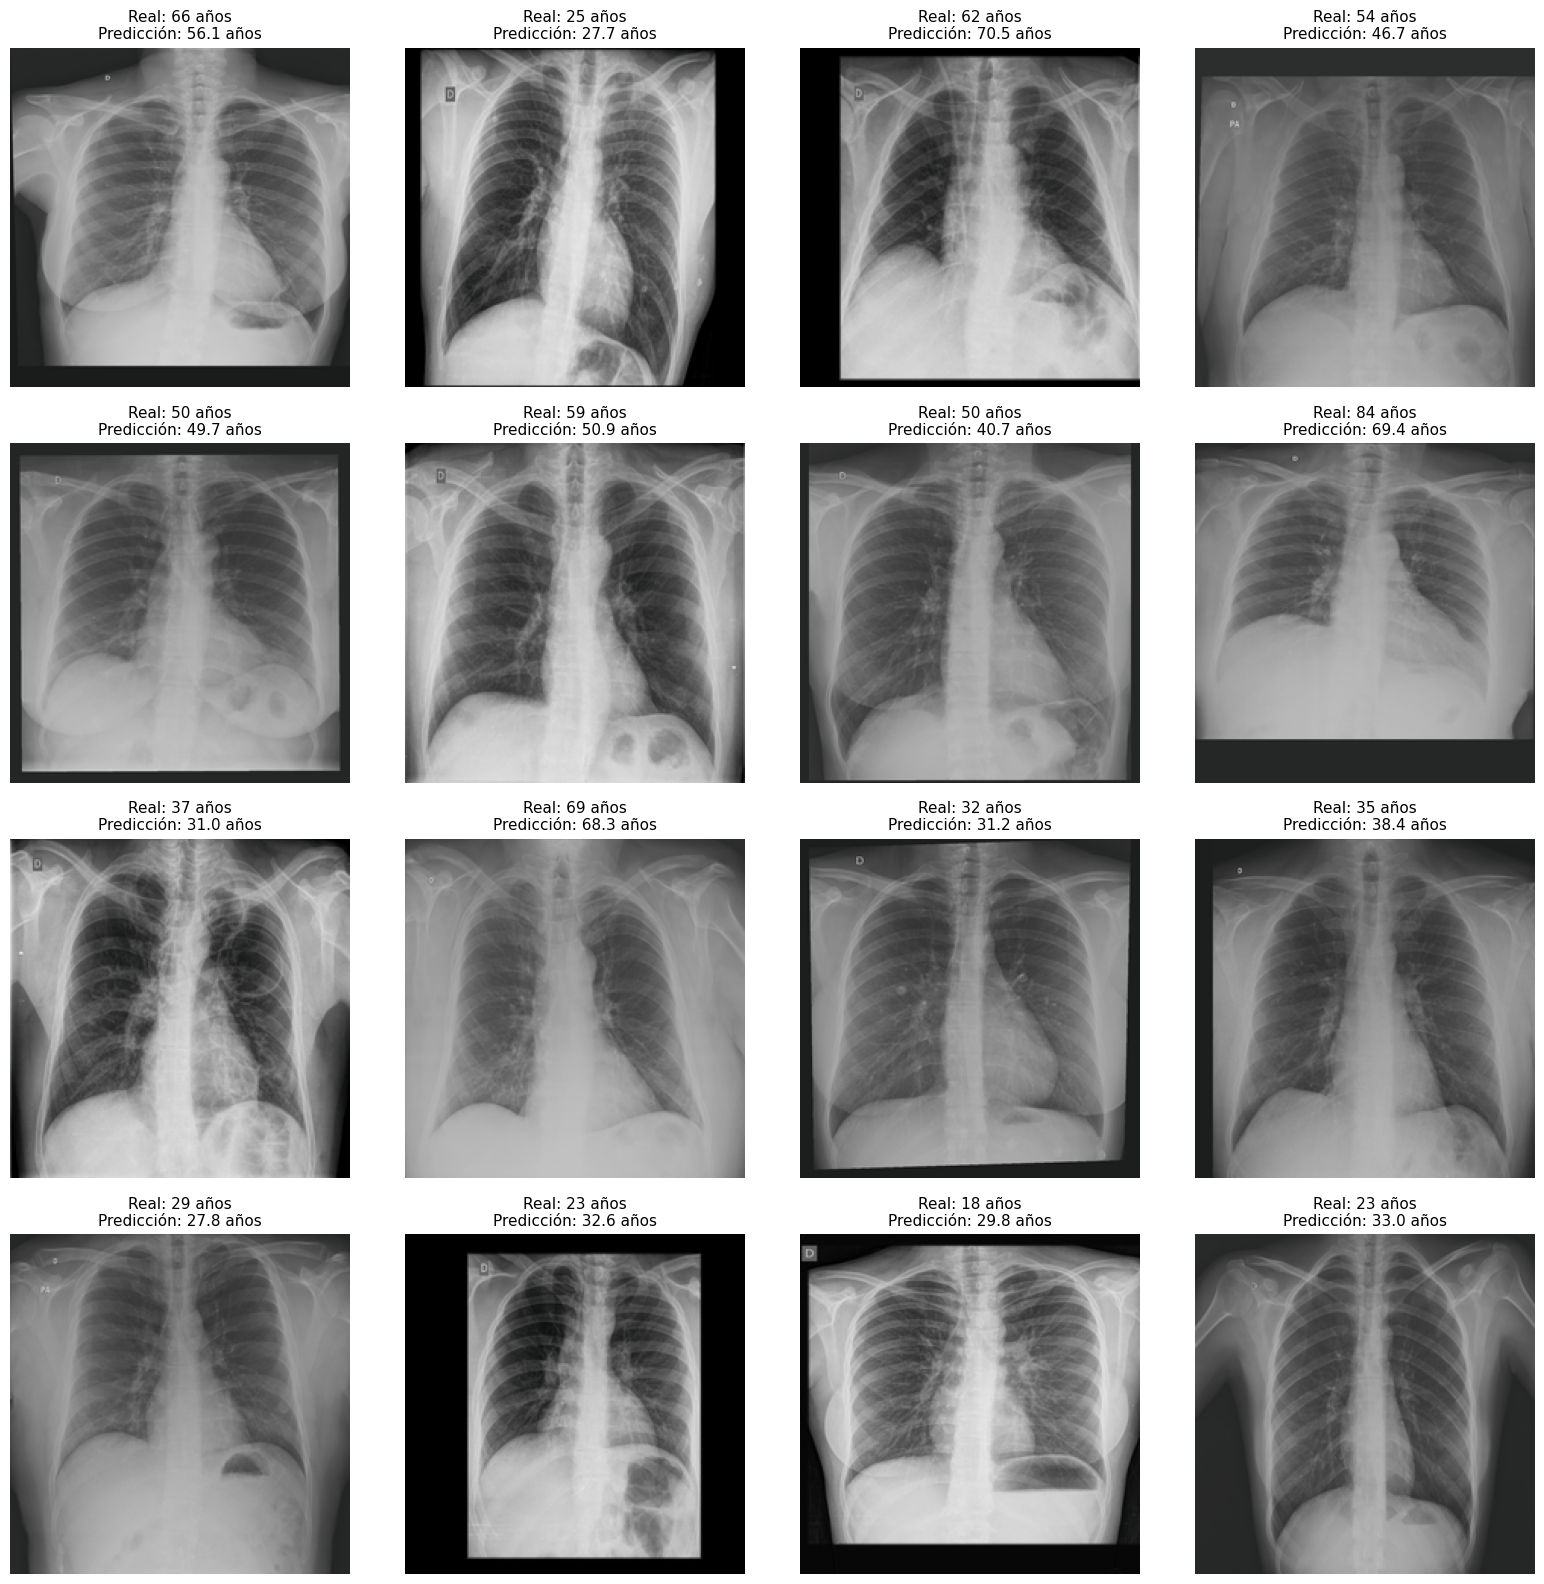

In [ ]:
show_regression_predictions(learn1)

In [ ]:
# A CUBRIR POR EL ALUMNADO



## <font color='blue'>3.2. ResNet50 se usa como extractor de características: Entrenamos única y exclusivamente la cabecera incorporada (1.25 puntos, incluidos los 0.5 puntos de las dos cuestiones adicionales)



In [ ]:
# A CUBRIR POR EL ALUMNADO

### <font color='blue'>Si no se especifica ninguna `custom_head`, ¿qué incorpora fastai por defecto? Entrena el modelo utilizando dicha cabecera y compara sus resultados con los obtenidos mediante la cabecera personalizada. ¿Qué diferencias existen entre ambas arquitecturas? ¿Qué conclusiones puedes extraer en términos de rendimiento y número de parámetros entrenables? (0.25 ptos)

In [ ]:
# A CUBRIR POR EL ALUMNADO

### <font color='blue'> Estamos intentando resolver un problema de regresión por medio de la reutilización de un modelo pre-entrenado en un problema de clasificación (ImageNet). ¿Tiene sentido hacerlo? ¿Por qué nos sirven pesos entrenados en clasificación para un problema de regresión? ¿No son, acaso, problemáticas muy diferentes? (0.25 ptos)

## <font color='blue'>3.3. Hacemos un ajuste fino (fine-tuning) de toda la red partiendo de los pesos de ImageNet (0.75 puntos)

In [ ]:
# A CUBRIR POR EL ALUMNADO

## <font color='blue'>3.4. Hacemos un ajuste fino (fine-tuning) de toda la red partiendo de los pesos de ImageNet, pero enfocando el problema como uno de clasificación (1 punto)

In [ ]:
# A CUBRIR POR EL ALUMNADO

## <font color='blue'>3.5. Diseño y evaluación de una arquitectura alternativa para regresión (1 punto)

<font color='blue'>El objetivo es investigar si una arquitectura más pequeña, con una cabecera diseñada específicamente para este problema, puede ofrecer un rendimiento competitivo respecto a ResNet50, utilizando menos parámetros y recursos computacionales.

In [ ]:
# A CUBRIR POR EL ALUMNADO

## <font color='blue'>3.6. ¿Qué conclusiones se pueden extraer en base a toda la experimentación anterior? En caso de que nos enfrentemos a un nuevo problema, ¿qué opción, u opciones, de entre todas las anteriores, parece a priori la más razonable? ¿Por qué? (0.25 puntos)